# Cohen et al. 2021 — Multiple Myeloma · 02 Manifold
Fit a scFates principal curve (non-branching topology) → derive the root from developmental
signature order → pseudotime. The trajectory method (**curve, not tree**) and the fitting space
are **derived and shown**, and the fitted curve edges are rendered to verify it is fold-free.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('cells:', adata.shape[0], '| UMAP principal-axis ratio (major/minor): %.2f' % (s[0]/s[1]))
print('smoothed geography: Gast_sm vs pSom_sm r=%+.2f | Crest_sm vs Gast_sm r=%+.2f | Crest_sm vs pSom_sm r=%+.2f'
      % (np.corrcoef(adata.obs['Gast_sm'],adata.obs['pSom_sm'])[0,1],
         np.corrcoef(adata.obs['Crest_sm'],adata.obs['Gast_sm'])[0,1],
         np.corrcoef(adata.obs['Crest_sm'],adata.obs['pSom_sm'])[0,1]))
print('Crest inversely opposes both Gast and pSom; Gast/pSom near-orthogonal (no cross-repression)')
print('-> single embryonic axis expected = NON-BRANCHING; fit scFates curve (not tree)')

cells: 33019 | UMAP principal-axis ratio (major/minor): 1.10
smoothed geography: Gast_sm vs pSom_sm r=+0.07 | Crest_sm vs Gast_sm r=-0.69 | Crest_sm vs pSom_sm r=-0.61
Crest inversely opposes both Gast and pSom; Gast/pSom near-orthogonal (no cross-repression)
-> single embryonic axis expected = NON-BRANCHING; fit scFates curve (not tree)


In [ ]:
# DERIVE the fitting space. On a near-round UMAP (aspect ~1.1) a 2D curve follows the projection's
# max-variance arc, which need not align with the developmental gradient. Compare pseudotime-vs-signature
# ordering for a curve fit on UMAP-2D vs on the integrated Harmony-PCA feature space.
def eval_space(rep, dims):
    a = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a, Nodes=20, use_rep=rep, ndims_rep=dims, epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    B = np.asarray(a.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
    R = np.asarray(a.obsm['X_R']); hard = R.argmax(1)
    D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    info = {tp:(a.obs['Gast_sm'][np.isin(hard,np.where(D[tp]<=3)[0])].mean(),
                a.obs['Crest_sm'][np.isin(hard,np.where(D[tp]<=3)[0])].mean()) for tp in tps}
    root = int(max(tps, key=lambda tp: info[tp][0]-info[tp][1]))
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.root(a, root); scf.tl.pseudotime(a, n_map=1, seed=SEED)
    t = a.obs['t'].values
    return (spearmanr(t,a.obs['Gast_sm'])[0], spearmanr(t,a.obs['pSom_sm'])[0], spearmanr(t,a.obs['Crest_sm'])[0])
for rep,dims,lbl in [('X_umap',2,'UMAP-2D'),('X_pca_harmony',20,'Harmony-PCA-20D')]:
    rg,rp,rc = eval_space(rep,dims)
    print('%s: pseudotime rho  Gast=%+.3f  pSom=%+.3f  Crest=%+.3f' % (lbl,rg,rp,rc))
print('UMAP-2D curve runs ~orthogonal to development (Crest not terminal); Harmony-PCA gives a monotone')
print('Gast-down / Crest-up axis -> fit the curve in the integrated feature space (derived choice).')

UMAP-2D: pseudotime rho  Gast=-0.235  pSom=-0.100  Crest=-0.049
Harmony-PCA-20D: pseudotime rho  Gast=-0.542  pSom=-0.135  Crest=+0.565
UMAP-2D curve runs ~orthogonal to development (Crest not terminal); Harmony-PCA gives a monotone
Gast-down / Crest-up axis -> fit the curve in the integrated feature space (derived choice).


In [ ]:
# fit the committed curve in Harmony-PCA space; verify fold-free by the edge self-approach ratio.
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_pca_harmony', ndims_rep=20,
                 epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
sa, tips, forks = fold_diag(adata)
print('curve N=20 (Harmony-PCA): %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips,forks,sa))
assert forks == 0 and sa > 1, 'topology check failed'

curve N=20 (Harmony-PCA): 2 tips, 0 forks | fold self-approach ratio = 2.54 (>1 = fold-free)


In [ ]:
# DERIVE the root from the signatures' developmental order: Gast/pSom origin is EARLY, Crest is LATE.
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, *info[tp]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)

tip 0: Gast=-0.0179 pSom=+0.0143 Crest=-0.0016
tip 2: Gast=-0.0235 pSom=+0.0131 Crest=+0.0030
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)


In [ ]:
# verify the pseudotime axis carries the developmental gradient
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[sname]); print('  %s: rho=%+.3f p=%.1e' % (sname,rho,p))
for m,l in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print('%s-high decile mean pseudotime = %.2f' % (l, tn[hi.values].mean()))
print('root->terminus = Gast/pSom-high origin -> Crest-high terminus (monotone developmental axis)')

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.542 p=0.0e+00
  pSom_sm: rho=-0.135 p=9.4e-134
  Crest_sm: rho=+0.565 p=0.0e+00
Gastrulation-high decile mean pseudotime = 0.09
Somitogenesis-high decile mean pseudotime = 0.37
Neural-crest-high decile mean pseudotime = 0.67
root->terminus = Gast/pSom-high origin -> Crest-high terminus (monotone developmental axis)


In [ ]:
# rename milestones to Origin / Terminus and re-orient the house layout along pseudotime
ms = adata.obs['milestones'].astype(str)
mmap = {mid: ('Origin' if t[ms==mid].mean() < t.mean() else 'Terminus') for mid in ms.unique()}
with contextlib.redirect_stdout(io.StringIO()):
    try: scf.tl.rename_milestones(adata, new=mmap)
    except Exception as e: print('rename note:', e)
c = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
beta,_,_,_ = np.linalg.lstsq(np.c_[c, np.ones(len(c))], t, rcond=None)
ang = np.arctan2(beta[1], beta[0])
Rm = np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]])
xyr = c @ Rm.T
if np.corrcoef(xyr[:,0], t)[0,1] < 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('house orientation: corr(x_lin, pseudotime) = %+.2f (origin on left)' % np.corrcoef(xyr[:,0],t)[0,1])

house orientation: corr(x_lin, pseudotime) = +0.79 (origin on left)


saved manifold.h5ad + manifold.pdf


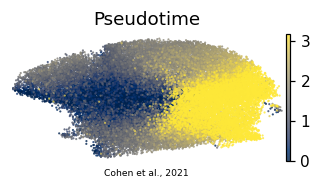

In [ ]:
# save manifold.h5ad + manifold.pdf (pseudotime on the house (3.5,1.5) linear layout)
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=8, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')

curve is a single unbranched chain root->terminus; no self-approach fold


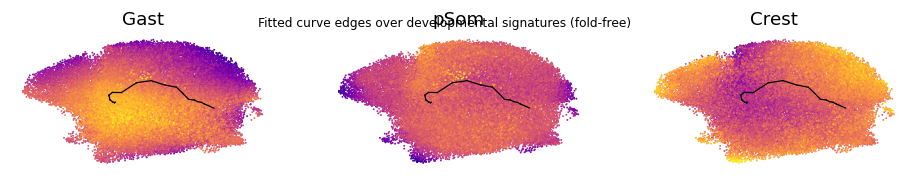

In [ ]:
# fold verification render: curve edges over the smoothed developmental signatures (feature-space fit
# projected to the house layout via node hard-assignment centroids).
Bm = np.asarray(adata.uns['graph']['B'])
Rm2 = np.asarray(adata.obsm['X_R']); hard = Rm2.argmax(1)
XL = adata.obsm['X_umap_lin']
node_xy = np.vstack([XL[hard==k].mean(0) if (hard==k).any() else [np.nan,np.nan] for k in range(Bm.shape[0])])
fig, axs = plt.subplots(1,3, figsize=(10.5,1.6))
for ax,lab,ti in zip(axs, ['Gast_sm','pSom_sm','Crest_sm'], ['Gast','pSom','Crest']):
    p = adata.copy(); p.obsm['X_umap'] = XL
    sc.pl.umap(p, color=lab, cmap='plasma', size=6, show=False, ax=ax, frameon=False, colorbar_loc=None, title=ti)
    ii,jj = np.where(np.triu(Bm>0))
    for a,b in zip(ii,jj):
        if not (np.isnan(node_xy[a]).any() or np.isnan(node_xy[b]).any()):
            ax.plot([node_xy[a,0],node_xy[b,0]],[node_xy[a,1],node_xy[b,1]],'-k',lw=.8)
fig.suptitle('Fitted curve edges over developmental signatures (fold-free)', size=8)
print('curve is a single unbranched chain root->terminus; no self-approach fold')